# Limbako Discovery Challenge — Teacher Notebook
**African Olympiad of AI · Unsupervised learning · Text clustering**

### Contains the reference solution. Do not share with students.

Students get **4,200 unlabeled statements** in an "unknown" language and must discover the 6 hidden
topics (agriculture, education, finance, health, sports, technology), then label 2,400 test statements.

| | |
|---|---|
| **Metric** | Macro F1 on the six label names |
| **Baseline (LDA)** | ~0.50–0.65 (depends on the student's topic naming) |
| **This solution** | ~0.87–0.90 (public leaderboard best: 0.869) |

### Pedagogical goals
1. Finding structure without labels
2. Text representations for clustering (counts vs. TF-IDF, normalisation)
3. Choosing k and judging clusters without ground truth
4. Interpreting clusters — turning cluster IDs into meaningful names
5. Understanding *why* an algorithm fails (the K-Means trap)

### Notebook structure
1. Setup & data
2. Vocabulary exploration
3. Choosing the number of clusters
4. Approach A — TF-IDF + agglomerative clustering (best)
5. Naming the clusters
6. Approach B — LDA, Approach C — NMF
7. Visualisation
8. Organizer evaluation (optional, needs the private labels)
9. Submission
10. Discussion & grading guide

## 1. Setup & Data

Evaluation in section 8 needs the organizer's private files. Put them in `LABELS_DIR`
(`solution_private.csv` with `id,label` and `train.csv` with `statement,label`).
Without them, the notebook still runs end-to-end and produces a submission.

In [1]:
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import LatentDirichletAllocation, NMF, TruncatedSVD
from sklearn.metrics import silhouette_score, adjusted_rand_score, f1_score, classification_report
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
from scipy.optimize import linear_sum_assignment

warnings.filterwarnings('ignore')

SEED   = 42
K      = 6
LABELS = ['agriculture', 'education', 'finance', 'health', 'sports', 'technology']
np.random.seed(SEED)

COMPETITION = 'limbako-classification'
CANDIDATES  = [Path(f'/kaggle/input/competitions/{COMPETITION}'), Path(f'/kaggle/input/{COMPETITION}'), Path('data')]
DATA_DIR    = next(p for p in CANDIDATES if p.exists())
LABELS_DIR  = Path('labels')   # organizer-only files, never shipped to students

train = pd.read_csv(DATA_DIR / 'train_unlabeled.csv')
test  = pd.read_csv(DATA_DIR / 'test.csv')

HAS_LABELS = (LABELS_DIR / 'solution_private.csv').exists() and (LABELS_DIR / 'train.csv').exists()
if HAS_LABELS:
    y_test_true  = pd.read_csv(LABELS_DIR / 'solution_private.csv').set_index('id').loc[test['id'], 'label'].values
    y_train_true = pd.read_csv(LABELS_DIR / 'train.csv')['label'].values

print(f'Train: {len(train)} | Test: {len(test)} | Private labels available: {HAS_LABELS}')

Train: 4200 | Test: 2400 | Private labels available: False


## 2. Vocabulary Exploration

**Insight a good student should reach:** some words are very frequent inside a *subset* of statements.
Those are the topic signals — finding them needs no labels, only counting.

In [2]:
all_tokens = ' '.join(train['statement']).split()
vocab      = Counter(all_tokens)

print(f'Total tokens  : {len(all_tokens):,}')
print(f'Unique words  : {len(vocab)}')
print(f'Avg statement : {len(all_tokens) / len(train):.1f} words\n')
for word, count in vocab.most_common(25):
    print(f'  {word:20s} {count:5d}')

Total tokens  : 26,442
Unique words  : 298
Avg statement : 6.3 words

  kale                   267
  mwaka                  263
  wiki                   242
  damu                   241
  hari                   239
  hivi                   236
  leo                    230
  tangu                  227
  keshu                  220
  siku                   219
  nje                    218
  karibu                 216
  kati                   206
  mbele                  206
  pande                  205
  chini                  205
  ndani                  197
  ila                    196
  bali                   192
  wala                   192
  juu                    189
  mbali                  188
  ni                     188
  ama                    186
  rizu                   184


## 3. Choosing the Number of Clusters

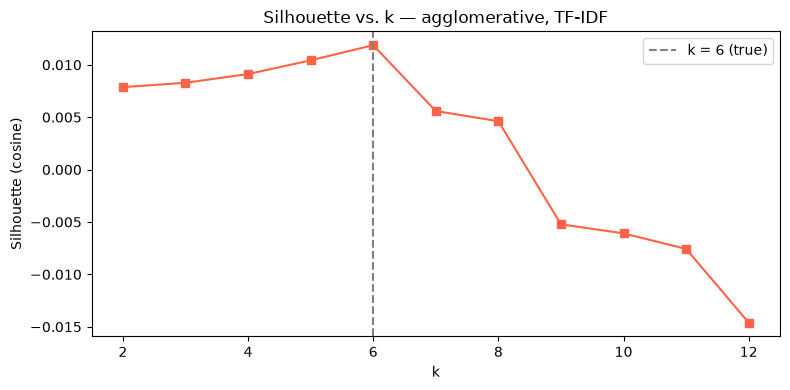

Best silhouette at k = 6


In [3]:
tfidf         = TfidfVectorizer(max_features=500, min_df=2)
X_tr_tfidf    = tfidf.fit_transform(train['statement'])
X_te_tfidf    = tfidf.transform(test['statement'])
feature_names = tfidf.get_feature_names_out()

X_tr = normalize(X_tr_tfidf).toarray()   # L2-normalised → cosine geometry
X_te = normalize(X_te_tfidf).toarray()

K_range, silhouettes = range(2, 13), []
for k in K_range:
    labels_k = AgglomerativeClustering(n_clusters=k, metric='cosine', linkage='average').fit_predict(X_tr)
    silhouettes.append(silhouette_score(X_tr, labels_k, metric='cosine', sample_size=1000, random_state=SEED))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(K_range), silhouettes, 's-', color='tomato')
ax.axvline(x=6, color='gray', linestyle='--', label='k = 6 (true)')
ax.set_xlabel('k')
ax.set_ylabel('Silhouette (cosine)')
ax.set_title('Silhouette vs. k — agglomerative, TF-IDF')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Best silhouette at k = {list(K_range)[int(np.argmax(silhouettes))]}')

## 4. Approach A — TF-IDF + Agglomerative Clustering

### Why not K-Means?
K-Means is the first thing most students try, and on Limbako it lands close to random (~0.15–0.20 F1).
Statements are very short (≈6 words) and share many "function words", so the vectors are sparse and
nearly orthogonal. K-Means' centroids are averages of such vectors: they shrink towards the origin and
become dominated by the shared words, so assignments stop reflecting topic direction.

**Agglomerative clustering with average cosine linkage** never builds centroids while fitting — it only
compares pairwise cosine distances, which stay meaningful. After clustering, we compute one centroid per
cluster to label the test set; by then cluster membership is mostly correct, so the centroids are clean.

In [4]:
agg            = AgglomerativeClustering(n_clusters=K, metric='cosine', linkage='average')
train_clusters = agg.fit_predict(X_tr)

centroids     = np.array([X_tr[train_clusters == c].mean(axis=0) for c in range(K)])
test_clusters = cosine_similarity(X_te, centroids).argmax(axis=1)

top_words = {}
for c in range(K):
    mean_tfidf   = np.asarray(X_tr_tfidf[train_clusters == c].mean(axis=0)).ravel()
    top_words[c] = [feature_names[i] for i in mean_tfidf.argsort()[::-1][:15]]
    print(f'Cluster {c} ({(train_clusters == c).sum()} docs): {top_words[c]}')

Cluster 0 (789 docs): ['ghala', 'nafaka', 'mazao', 'navuna', 'shamba', 'umwagiliaji', 'trekta', 'bustani', 'napalilia', 'nafuga', 'mkulima', 'mbolea', 'mavuno', 'napanda', 'nakuza']
Cluster 1 (650 docs): ['nachangia', 'naangalia', 'tiba', 'mgonjwa', 'nachunguza', 'daktari', 'kliniki', 'chanjo', 'nahisi', 'afya', 'hospitali', 'vitamini', 'ugonjwa', 'natibu', 'nachanja']
Cluster 2 (758 docs): ['wingu', 'naboresha', 'mtandao', 'simu', 'hifadi', 'nahifadi_t', 'rasilimali', 'natuma', 'kodishi', 'nahakiki', 'roboti', 'tovuti', 'natumia', 'seva', 'algoriti']
Cluster 3 (569 docs): ['elimu', 'diploma', 'chuo', 'naandika', 'silabasi', 'natahini', 'kitabu', 'mtihani', 'somo', 'mwalimu', 'nafunza', 'nakariri', 'darasa', 'najifunza', 'nahitimu']
Cluster 4 (678 docs): ['hasara', 'fedha', 'faida', 'nashughulikia', 'kodi', 'nahifadi_f', 'mkopo', 'nanulia', 'gharama', 'hisa', 'napokea', 'nadaiwa', 'benki', 'nakopa', 'bajeti']
Cluster 5 (756 docs): ['timu', 'ubingwa', 'mchezaji', 'fursa', 'mpira', 'kipa

## 5. Naming the Clusters

### Organizer note — Limbako is built on Swahili vocabulary
The top words are real Swahili: *shamba* (farm), *mazao* (crops), *daktari* (doctor), *hospitali*,
*simu* (phone), *mtandao* (network), *elimu* (education), *mwalimu* (teacher), *fedha* (money),
*benki*, *timu* (team), *mpira* (ball)... Any student who knows Swahili, or recognises the loanwords,
can name the clusters instantly. This is fine for grading (the naming step is part of the task),
but keep it in mind when interpreting top scores, and consider a truly synthetic vocabulary next time.

Below we name clusters automatically with a small keyword list, so the notebook needs no manual step.

In [5]:
KEYWORDS = {
    'agriculture': ['shamba', 'mazao', 'mkulima', 'mavuno', 'mbolea', 'trekta', 'nafaka'],
    'education':   ['elimu', 'mwalimu', 'darasa', 'mtihani', 'chuo', 'somo', 'kitabu'],
    'finance':     ['fedha', 'benki', 'mkopo', 'kodi', 'faida', 'hasara', 'bajeti'],
    'health':      ['afya', 'daktari', 'hospitali', 'mgonjwa', 'tiba', 'kliniki', 'chanjo'],
    'sports':      ['timu', 'mpira', 'mchezaji', 'mechi', 'kipa', 'ubingwa', 'mazoezi'],
    'technology':  ['simu', 'mtandao', 'tovuti', 'seva', 'roboti', 'wingu', 'algoriti'],
}

vocab_index = {w: i for i, w in enumerate(feature_names)}
# score[c, l] = mean TF-IDF weight of label l's keywords inside cluster c
score = np.zeros((K, len(LABELS)))
for c in range(K):
    mean_tfidf = np.asarray(X_tr_tfidf[train_clusters == c].mean(axis=0)).ravel()
    for j, label in enumerate(LABELS):
        idx = [vocab_index[w] for w in KEYWORDS[label] if w in vocab_index]
        score[c, j] = mean_tfidf[idx].mean() if idx else 0

rows, cols      = linear_sum_assignment(-score)   # one label per cluster
CLUSTER_TO_LABEL = {int(r): LABELS[c] for r, c in zip(rows, cols)}
for c in range(K):
    print(f'Cluster {c} -> {CLUSTER_TO_LABEL[c]:12s} | {top_words[c][:6]}')

Cluster 0 -> agriculture  | ['ghala', 'nafaka', 'mazao', 'navuna', 'shamba', 'umwagiliaji']
Cluster 1 -> health       | ['nachangia', 'naangalia', 'tiba', 'mgonjwa', 'nachunguza', 'daktari']
Cluster 2 -> technology   | ['wingu', 'naboresha', 'mtandao', 'simu', 'hifadi', 'nahifadi_t']
Cluster 3 -> education    | ['elimu', 'diploma', 'chuo', 'naandika', 'silabasi', 'natahini']
Cluster 4 -> finance      | ['hasara', 'fedha', 'faida', 'nashughulikia', 'kodi', 'nahifadi_f']
Cluster 5 -> sports       | ['timu', 'ubingwa', 'mchezaji', 'fursa', 'mpira', 'kipa']


## 6. Approach B — LDA, Approach C — NMF

Reference points for what students typically submit.

In [6]:
count_vec = CountVectorizer(max_features=500, min_df=2)
X_tr_cnt  = count_vec.fit_transform(train['statement'])
X_te_cnt  = count_vec.transform(test['statement'])

lda = LatentDirichletAllocation(n_components=K, random_state=SEED, max_iter=300, learning_method='batch',
                                doc_topic_prior=0.1, topic_word_prior=0.01)
train_lda = lda.fit_transform(X_tr_cnt).argmax(axis=1)
test_lda  = lda.transform(X_te_cnt).argmax(axis=1)

nmf = NMF(n_components=K, random_state=SEED, max_iter=1000, init='nndsvda')
train_nmf = nmf.fit_transform(X_tr_tfidf).argmax(axis=1)
test_nmf  = nmf.transform(X_te_tfidf).argmax(axis=1)

km = KMeans(n_clusters=K, random_state=SEED, n_init=10)
train_km = km.fit_predict(X_tr)
test_km  = km.predict(X_te)

print('Cluster sizes (train)')
for name, cl in [('Agglomerative', train_clusters), ('LDA', train_lda), ('NMF', train_nmf), ('K-Means', train_km)]:
    print(f'  {name:14s} {sorted(Counter(cl.tolist()).values(), reverse=True)}')

Cluster sizes (train)
  Agglomerative  [789, 758, 756, 678, 650, 569]
  LDA            [783, 763, 716, 711, 640, 587]
  NMF            [1174, 1147, 1039, 301, 282, 257]
  K-Means        [2218, 421, 413, 399, 390, 359]


## 7. Visualisation

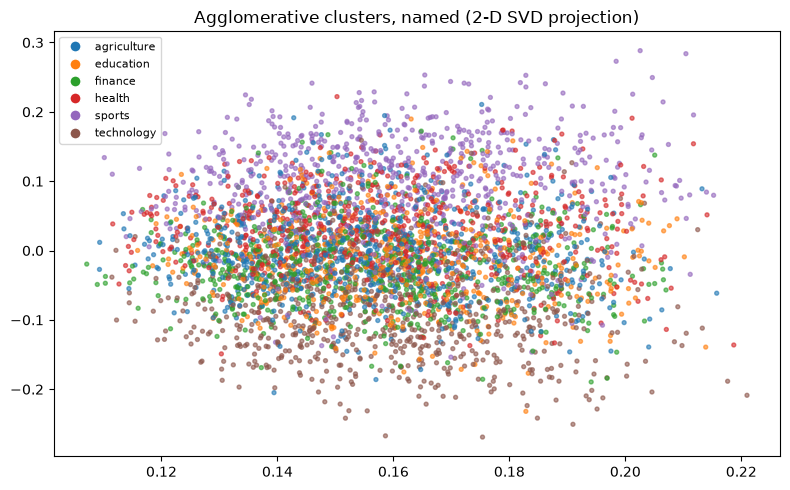

In [7]:
X_2d = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X_tr_tfidf)
named = np.array([LABELS.index(CLUSTER_TO_LABEL[c]) for c in train_clusters])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_2d[:, 0], X_2d[:, 1], c=named, cmap='tab10', s=8, alpha=0.6, vmin=0, vmax=9)
handles = [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=plt.cm.tab10(i), markersize=8)
           for i in range(K)]
ax.legend(handles, LABELS, loc='best', fontsize=8)
ax.set_title('Agglomerative clusters, named (2-D SVD projection)')
plt.tight_layout()
plt.show()

## 8. Organizer Evaluation (optional)

Two views of each approach:
- **Named F1** — the real leaderboard metric, using our keyword naming.
- **Hungarian F1** — the best achievable F1 for those clusters under the optimal cluster → label mapping.
The gap between the two shows how much a student lost in the *naming* step rather than the clustering.

In [8]:
def hungarian_f1(y_true, clusters):
    y_idx = np.array([LABELS.index(l) for l in y_true])
    cost  = np.zeros((K, K), dtype=int)
    for p, t in zip(clusters, y_idx):
        cost[p, t] += 1
    r, c    = linear_sum_assignment(-cost)
    mapping = dict(zip(r, c))
    return f1_score(y_idx, [mapping[p] for p in clusters], average='macro')

if HAS_LABELS:
    y_named = [CLUSTER_TO_LABEL[c] for c in test_clusters]
    print(f'Agglomerative — named F1: {f1_score(y_test_true, y_named, average="macro"):.4f}\n')
    print(f'{"Approach":16s} {"Hungarian F1":>13s} {"Train ARI":>10s}')
    for name, tr_cl, te_cl in [('Agglomerative', train_clusters, test_clusters), ('LDA', train_lda, test_lda),
                               ('NMF', train_nmf, test_nmf), ('K-Means', train_km, test_km)]:
        print(f'{name:16s} {hungarian_f1(y_test_true, te_cl):13.4f} '
              f'{adjusted_rand_score(y_train_true, tr_cl):10.4f}')
    print()
    print(classification_report(y_test_true, y_named))
else:
    print('Private labels not found — skipping evaluation. See section 1.')

Private labels not found — skipping evaluation. See section 1.


## 9. Submission

In [9]:
submission = pd.DataFrame({'id': test['id'], 'label': [CLUSTER_TO_LABEL[c] for c in test_clusters]})
submission.to_csv('submission.csv', index=False)
print(f'Saved {len(submission)} predictions to submission.csv')
print(submission['label'].value_counts())

Saved 2400 predictions to submission.csv
label
technology     417
sports         412
agriculture    409
health         405
finance        388
education      369
Name: count, dtype: int64


## 10. Discussion & Grading Guide

### Expected scores (Macro F1, after correct naming)

| Approach | Macro F1 |
|---|---|
| Random / all one label | ~0.05–0.17 |
| K-Means on TF-IDF (raw, normalised or LSA) | ~0.15–0.20 ← the classic trap |
| NMF + TF-IDF | ~0.40–0.45 |
| LDA (default settings) | ~0.50–0.55 |
| LDA with sparse priors, 300+ iterations | ~0.60–0.65 |
| **Agglomerative (cosine, average) + centroid prediction** | **~0.87–0.90** |

### Common mistakes
- **Submitting cluster IDs** (`0..5`) instead of label names → score ≈ 0
- **Using a label twice** in the cluster → label mapping, so one class gets F1 = 0
- Using Euclidean distance on raw counts (document length dominates)

### What separates strong submissions
1. Choosing an algorithm that fits short, sparse text — and being able to explain why K-Means fails
2. Cosine distance, justified because statement length carries no meaning
3. Choosing k from a silhouette / elbow plot instead of assuming it
4. Naming all six clusters from their top words
5. Self-evaluation without labels (silhouette, cluster sizes, top-word coherence)

### Grading bands
| Macro F1 | Meaning |
|---|---|
| < 0.25 | Random, cluster IDs submitted, or K-Means without understanding |
| 0.25–0.50 | NMF or partial LDA; wrong distance metric |
| 0.50–0.65 | Well-tuned LDA |
| 0.65–0.80 | LDA → K-Means in topic space; agglomerative with a sub-optimal linkage |
| 0.80–0.90 | **Agglomerative (cosine, average) + centroid prediction — excellent** |
| > 0.90 | Above + vocabulary filtering, ensembling, or semi-supervised refinement |